In [1]:
using LinearAlgebra, Plots

n = 100
epsilon = 1e-8
A = zeros(n, n)

for row in 1:n
    for col in row:n
        value = round(1 + 9 * rand(); digits=2)
        A[row, col] = value
        A[col, row] = value
    end
    A[row, row] = sum(A[row, :])
end

for row in 1:n
    A[row, row] = sum(A[row, :])
end

x_star = ones(n)
x0 = zeros(n)
f = A * x_star
println("Матрица A:")
display(A)

Матрица A:


100×100 Matrix{Float64}:
 1115.55     8.68     8.66    7.82  …     3.03     1.81     5.59     7.15
    8.68  1117.1      8.57    2.39        1.68     1.24     7.6      1.32
    8.66     8.57  1171.63    3.23        2.87     3.9      2.39     6.35
    7.82     2.39     3.23  941.8         5.2      6.99     6.73     5.21
    3.36     1.55     7.97    6.77        8.77     6.68     7.47     1.74
    4.93     4.54     5.14    1.48  …     4.94     5.91     6.89     7.51
    4.12     9.96     8.86    9.41        6.55     6.72     9.18     9.78
    1.35     5.33     6.57    1.04        5.78     5.45     4.33     8.65
    3.03     4.66     7.64    5.88        8.91     8.6      7.29     8.11
    9.25     3.76     4.93    3.62        9.59     3.71     6.98     1.58
    3.92     4.0      7.37    1.64  …     8.69     5.0      2.95     4.22
    4.03     6.15     8.54    2.9         9.93     6.13     6.8      5.89
    2.36     5.6      5.01    6.31        9.92     8.89     6.14     6.89
    ⋮        

In [2]:
lambda = eigvals(Symmetric(A))
lambda_min, lambda_max = extrema(lambda)

tau_limit = 2 / lambda_max
tau_opt = 2 / (lambda_min + lambda_max)
q0 = (lambda_max - lambda_min) / (lambda_max + lambda_min)

println("Интервал собственных значений: [", lambda_min, ", ", lambda_max, "]")
println("Оптимальное tau = ", tau_opt)
println("q0 = ", q0)

Интервал собственных значений: [935.1299406057626, 1647.780217687942]
Оптимальное tau = 0.00077432038957221
q0 = 0.27590982008950826


In [3]:
tau_step = min(tau_opt, tau_limit - tau_opt) / 3
tau_values = [tau_opt - 2 * tau_step, tau_opt - tau_step, tau_opt, tau_opt + tau_step, tau_opt + 2 * tau_step]
q_values = [max(abs(1 - tau * lambda_min), abs(1 - tau * lambda_max)) for tau in tau_values]

iteration_counts = Int[]
error_histories = Vector{Float64}[]

for tau in tau_values
    x = copy(x0)
    k = 0
    error_norm = norm(x - x_star)
    errors = [error_norm]
    while error_norm > epsilon && k < 10000
        x = x - tau * (A * x - f)
        k += 1
        error_norm = norm(x - x_star)
        push!(errors, error_norm)
    end
    push!(iteration_counts, k)
    push!(error_histories, errors)

    println("tau = ", tau)
    println("Количество итераций: ", k)
    println("Итоговая ошибка: ", error_norm)
    println("Левое расстояние до нуля: ", abs(1 - tau * lambda_min))
    println("Правое расстояние до нуля: ", abs(1 - tau * lambda_max))
    println()
end

tau = 0.0004813645806450186
Количество итераций: 30
Итоговая ошибка: 6.859197100400343e-9
Левое расстояние до нуля: 0.549861568291706
Правое расстояние до нуля: 0.20681696651748638

tau = 0.0006278424851086143
Количество итераций: 20
Итоговая ошибка: 8.587103695736436e-9
Левое расстояние до нуля: 0.41288569419060717
Правое расстояние до нуля: 0.03454642678601094

tau = 0.00077432038957221
Количество итераций: 17
Итоговая ошибка: 3.0698293545223e-9
Левое расстояние до нуля: 0.27590982008950826
Правое расстояние до нуля: 0.27590982008950826

tau = 0.0009207982940358057
Количество итераций: 32
Итоговая ошибка: 6.803980696869554e-9
Левое расстояние до нуля: 0.13893394598840947
Правое расстояние до нуля: 0.5172732133930056

tau = 0.0010672761984994014
Количество итераций: 75
Итоговая ошибка: 9.914209134746244e-9
Левое расстояние до нуля: 0.001958071887310675
Правое расстояние до нуля: 0.7586366066965029



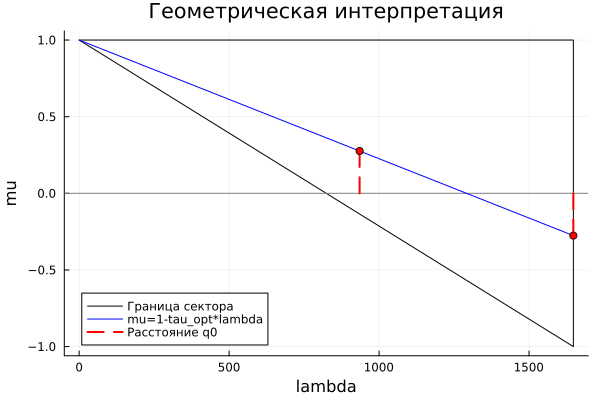

In [4]:
geometry = plot(
    [0, lambda_max, lambda_max, 0],
    [1, 1, -1, 1],
    label="Граница сектора",
    color=:black,
    xlabel="lambda",
    ylabel="mu",
    title="Геометрическая интерпретация"
)

hline!(
    geometry,
    [0],
    label=false,
    color=:gray
)

plot!(
    geometry,
    [0, lambda_max],
    [1, -q0],
    label="mu=1-tau_opt*lambda",
    color=:blue
)

plot!(
    geometry,
    [lambda_min, lambda_min],
    [0, q0],
    label="Расстояние q0",
    color=:red,
    linestyle=:dash,
    linewidth=2
)

plot!(
    geometry,
    [lambda_max, lambda_max],
    [-q0, 0],
    label=false,
    color=:red,
    linestyle=:dash,
    linewidth=2
)

scatter!(
    geometry,
    [lambda_min, lambda_max],
    [q0, -q0],
    label=false,
    color=:red
)

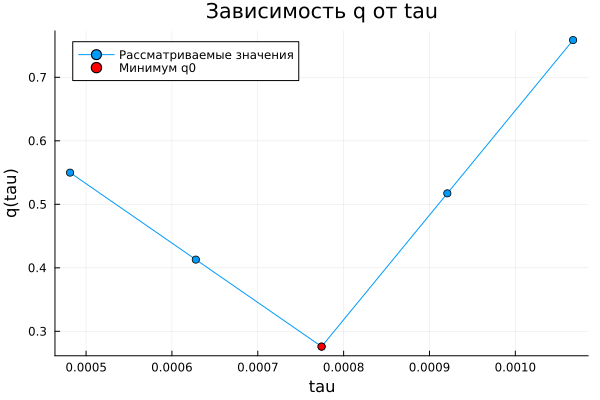

In [5]:
comparison = plot(
    tau_values,
    q_values,
    marker=:circle,
    label="Рассматриваемые значения",
    xlabel="tau",
    ylabel="q(tau)",
    title="Зависимость q от tau"
)

scatter!(
    comparison,
    [tau_opt],
    [q0],
    color=:red,
    label="Минимум q0"
)

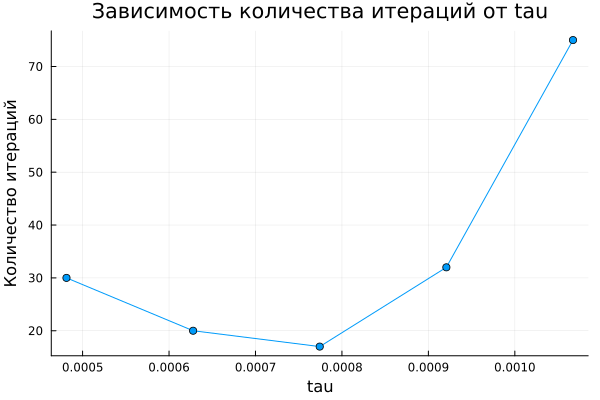

In [6]:
 plot(
    tau_values,
    iteration_counts,
    marker=:circle,
    legend=false,
    xlabel="tau",
    ylabel="Количество итераций",
    title="Зависимость количества итераций от tau"
)